In [1]:
import pandas as pd

app = pd.read_csv("../data/raw/application_train.csv")
print(app.shape)
print(app["TARGET"].mean())

(307511, 122)
0.08072881945686496


In [2]:
app.isna()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,True,True,True,True,True
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,True,True,True,True,True
307507,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,True,True,True,True,True
307508,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
307509,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [3]:
app.isna().mean()

SK_ID_CURR                    0.000000
TARGET                        0.000000
NAME_CONTRACT_TYPE            0.000000
CODE_GENDER                   0.000000
FLAG_OWN_CAR                  0.000000
                                ...   
AMT_REQ_CREDIT_BUREAU_DAY     0.135016
AMT_REQ_CREDIT_BUREAU_WEEK    0.135016
AMT_REQ_CREDIT_BUREAU_MON     0.135016
AMT_REQ_CREDIT_BUREAU_QRT     0.135016
AMT_REQ_CREDIT_BUREAU_YEAR    0.135016
Length: 122, dtype: float64

In [4]:
app.isna().mean().sort_values(ascending=False).head(20)

COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
COMMONAREA_MEDI             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_MODE       0.683550
FLOORSMIN_MODE              0.678486
FLOORSMIN_AVG               0.678486
FLOORSMIN_MEDI              0.678486
YEARS_BUILD_AVG             0.664978
YEARS_BUILD_MODE            0.664978
YEARS_BUILD_MEDI            0.664978
OWN_CAR_AGE                 0.659908
LANDAREA_MEDI               0.593767
LANDAREA_AVG                0.593767
LANDAREA_MODE               0.593767
dtype: float64

In [5]:
app.groupby("FLAG_OWN_CAR")["OWN_CAR_AGE"].apply(lambda s: s.isna().mean())

FLAG_OWN_CAR
N    1.000000
Y    0.000048
Name: OWN_CAR_AGE, dtype: float64

In [6]:
app["DAYS_EMPLOYED"].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [7]:
sentinel = app["DAYS_EMPLOYED"] == 365243
print(sentinel.mean())
print(app.loc[sentinel, "NAME_INCOME_TYPE"].value_counts())
print(app.groupby(sentinel)["TARGET"].mean())

0.18007160719453938
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64
DAYS_EMPLOYED
False    0.086600
True     0.053996
Name: TARGET, dtype: float64


In [8]:
from pathlib import Path

for dosya in sorted(Path("../data/raw").glob("*.csv")):
    kolonlar = pd.read_csv(dosya, nrows=0, encoding="latin-1").columns
    kimlikler = [k for k in kolonlar if k.startswith("SK_ID")]
    print(dosya.name, kimlikler)

application_test.csv ['SK_ID_CURR']
application_train.csv ['SK_ID_CURR']
bureau.csv ['SK_ID_CURR', 'SK_ID_BUREAU']
bureau_balance.csv ['SK_ID_BUREAU']
credit_card_balance.csv ['SK_ID_PREV', 'SK_ID_CURR']
HomeCredit_columns_description.csv []
installments_payments.csv ['SK_ID_PREV', 'SK_ID_CURR']
POS_CASH_balance.csv ['SK_ID_PREV', 'SK_ID_CURR']
previous_application.csv ['SK_ID_PREV', 'SK_ID_CURR']
sample_submission.csv ['SK_ID_CURR']


In [9]:
from pathlib import Path

for dosya in sorted(Path("../data/raw").glob("*.csv")):
    kolonlar = pd.read_csv(dosya, nrows=0, encoding="latin-1").columns
    kimlikler = [k for k in kolonlar if k.startswith("SK_ID")]
    print(dosya.name, kimlikler)

application_test.csv ['SK_ID_CURR']
application_train.csv ['SK_ID_CURR']
bureau.csv ['SK_ID_CURR', 'SK_ID_BUREAU']
bureau_balance.csv ['SK_ID_BUREAU']
credit_card_balance.csv ['SK_ID_PREV', 'SK_ID_CURR']
HomeCredit_columns_description.csv []
installments_payments.csv ['SK_ID_PREV', 'SK_ID_CURR']
POS_CASH_balance.csv ['SK_ID_PREV', 'SK_ID_CURR']
previous_application.csv ['SK_ID_PREV', 'SK_ID_CURR']
sample_submission.csv ['SK_ID_CURR']


In [10]:
bureau = pd.read_csv("../data/raw/bureau.csv", usecols=["SK_ID_CURR"])
kayitsiz = ~app["SK_ID_CURR"].isin(bureau["SK_ID_CURR"])
print(kayitsiz.sum(), kayitsiz.mean())
print(app.groupby(kayitsiz)["TARGET"].mean())

44020 0.14314935075493235
SK_ID_CURR
False    0.077301
True     0.101249
Name: TARGET, dtype: float64


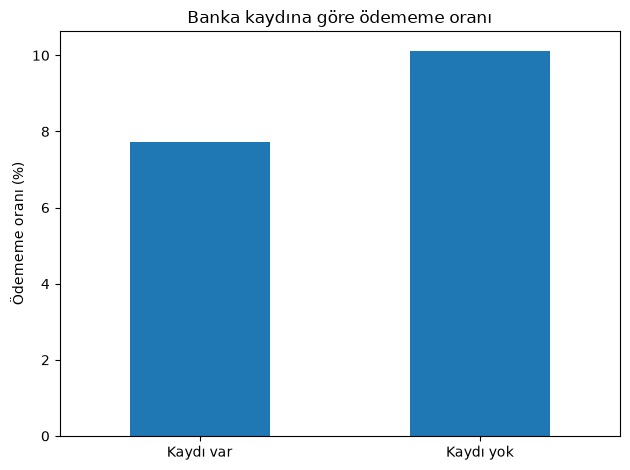

In [11]:
import matplotlib.pyplot as plt

Path("../reports/figures").mkdir(parents=True, exist_ok=True)

oranlar = app.groupby(kayitsiz)["TARGET"].mean() * 100
oranlar.index = ["Kaydı var", "Kaydı yok"]

ax = oranlar.plot(kind="bar", rot=0)
ax.set_ylabel("Ödememe oranı (%)")
ax.set_title("Banka kaydına göre ödememe oranı")
plt.tight_layout()
plt.savefig("../reports/figures/kayit_durumu.png", dpi=150)
plt.show()

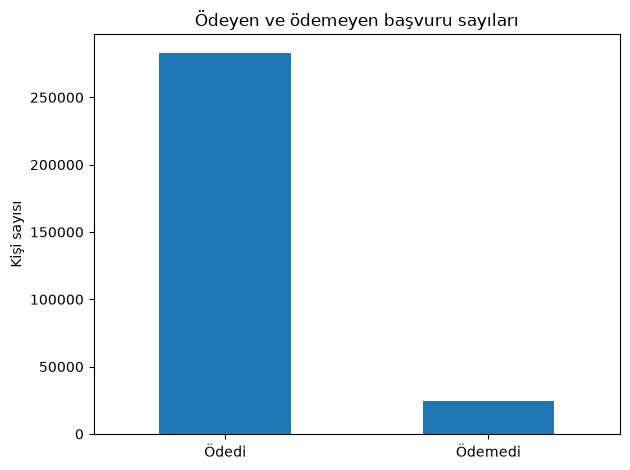

In [12]:
sayilar = app["TARGET"].value_counts()
sayilar.index = ["Ödedi", "Ödemedi"]

ax = sayilar.plot(kind="bar", rot=0)
ax.set_ylabel("Kişi sayısı")
ax.set_title("Ödeyen ve ödemeyen başvuru sayıları")
plt.tight_layout()
plt.savefig("../reports/figures/odeyen_odemeyen.png", dpi=150)
plt.show()

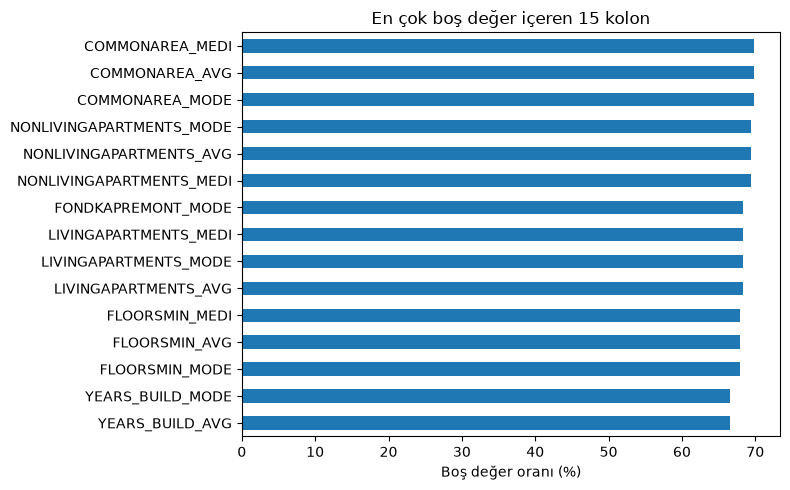

In [13]:
eksik = app.isna().mean().sort_values(ascending=False).head(15) * 100

ax = eksik.sort_values().plot(kind="barh", figsize=(8, 5))
ax.set_xlabel("Boş değer oranı (%)")
ax.set_title("En çok boş değer içeren 15 kolon")
plt.tight_layout()
plt.savefig("../reports/figures/eksik_kolonlar.png", dpi=150)
plt.show()

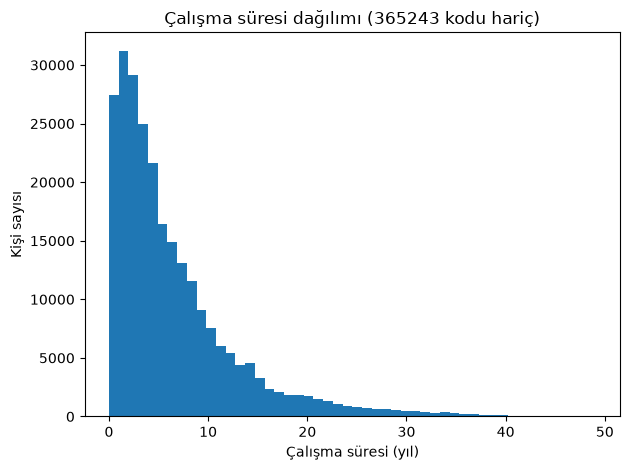

In [14]:
calisma_yili = app.loc[~sentinel, "DAYS_EMPLOYED"] / -365

ax = calisma_yili.plot(kind="hist", bins=50)
ax.set_xlabel("Çalışma süresi (yıl)")
ax.set_ylabel("Kişi sayısı")
ax.set_title("Çalışma süresi dağılımı (365243 kodu hariç)")
plt.tight_layout()
plt.savefig("../reports/figures/calisma_suresi.png", dpi=150)
plt.show()

## Veri tanıma bulguları

- 307.511 başvuru ve 122 kolon var. Başvuruların %8,1'inde ödeme güçlüğü yaşanmış.
- En çok boş kolonlar bina bilgileri, yaklaşık %60-70 boş. Modelde kullanılmayacak.
- `OWN_CAR_AGE` boşluğu araç sahibi olmamayla açıklanıyor, yani boşluk bilgi içeriyor.
- `DAYS_EMPLOYED = 365243` başvuruların %18'inde var ve neredeyse tamamı emekli.
- Bu grubun ödeme güçlüğü oranı %5,4, diğerlerinin %8,7.
- `bureau` kaydı olmayan 44.020 kişi var (%14,3). Oranları %10,1, kaydı olanlarda %7,7.
- Tablolar `SK_ID_CURR`, `SK_ID_BUREAU` ve `SK_ID_PREV` ile bağlanıyor.
- `bureau_balance` kişiye doğrudan bağlanmıyor, önce `SK_ID_BUREAU` ile `bureau` tablosuna gidilmeli.
- Ana tablo dışındaki tablolarda kişi başına birden çok satır olabilir, modelden önce özetlenmeli.
- Yaş modelden çıkarıldı, ancak emekli bilgisi yaşı dolaylı olarak ele verebilir. Aşama 7'de ölçülecek.
- `bureau` kaydının olmaması hiç kredi kullanmadığını kanıtlamaz, fark da neden-sonuç göstermez.